# Un décideur typé à probabilités par option est-il mieux calibré et plus robuste au bruit qu'un CamemBERT entièrement entraîné, avant et après recalibrage ?

> **En bref.** L'expérience ne permet pas de dire si le décideur typé est mieux calibré que CamemBERT. À cette échelle, la référence n'a presque rien appris, donc son ECE basse est triviale. Verdict non concluant. ECE recalibrée (bruité) : 0,143 [0,107 ; 0,204] pour Décideur typé Qwen3-0.6B + LoRA, contre 0,0225 [0,00667 ; 0,0676] pour CamemBERT-base fine-tuné (100 exemples de test, échelle réduite, chiffres indicatifs).

| | |
|---|---|
| **Question** | Après recalibrage par température sur 500 exemples, le décideur Qwen3-0.6B adapté par LoRA atteint une ECE sur texte bruité inférieure d'au moins 30 % relatif à celle d'un CamemBERT-base entraîné sur tout le jeu, sans perdre plus de 3 points d'exactitude sur texte propre. |
| **Référence** | CamemBERT-base fine-tuné — Classifieur CamemBERT-base fine-tuné sur tout le train (hors lot de calibration), logits restreints aux mêmes candidats que le décideur pour une comparaison à périmètre égal. |
| **Nouvelle approche** | Décideur typé Qwen3 + LoRA (probabilité par option) — Un petit LLM reçoit le texte et 8 options candidates lettrées et rend, en une passe, une distribution sur les lettres lue dans les logits du premier token, sans génération. Adapté par LoRA sur un sous-ensemble du train, puis recalibré. |
| **Données publiques** | [`DeepPavlov/banking77_fr`](https://huggingface.co/datasets/DeepPavlov/banking77_fr) (default) |
| **Métrique principale** | ECE recalibrée (bruité) (à minimiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle réduite (`SCALE = "reduced"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `normalize_fr` | Normalisation pour le WER en français : minuscules, apostrophes et tirets unifiés, ponctuation retirée. |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'text': 'text', 'label': 'label', 'received_at': 'received_at'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['Qwen/Qwen3-0.6B', 'almanach/camembert-base', 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'], 'full': ['Qwen/Qwen3-0.6B', 'almanach/camembert-base', 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = ['peft']
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=reduced  SEED=42  device=cpu  python=3.12.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Un classifieur qui annonce « 92 % » ne sert à router un message client tout seul que si ce chiffre a un sens : sur 100 décisions annoncées à 92 %, environ 92 doivent être justes. C'est ce qu'on appelle la **calibration**. Une étude récente sur les *modèles de décision* trouve qu'ils sont mieux calibrés qu'un LLM génératif. Ces modèles ne génèrent pas de texte : ils rendent, en une seule passe, une probabilité pour chaque option déclarée. Mais l'étude porte sur l'anglais et ne les compare à aucun encodeur entraîné.

Ici, la question devient : sur des requêtes clients en français (services financiers), propres ou bruitées, un **décideur typé** est-il mieux calibré qu'un **CamemBERT entièrement entraîné**, avant et après recalibrage ?

### L'idée de la nouvelle approche

Analogie : au lieu de demander « quelle est l'intention ? » sans aucune piste, on tend un **QCM** au modèle, puis on regarde quelle part de sa « mise » il place sur chaque lettre. Les étapes :

1. **présélection** de 8 intentions candidates par similarité d'embeddings (étape commune aux deux approches) ;
2. **état + question Choice** : le message, puis les 8 options lettrées A–H, dans un ordre mélangé ;
3. **une seule passe** dans Qwen3-0.6B adapté par LoRA : on lit les logits des 8 lettres au premier token de la réponse, puis un softmax donne une probabilité par option, sans génération ;
4. **recalibrage** par une température unique, ajustée sur un lot de messages propres mis de côté ;
5. **mesure** sur trois versions du test : texte propre, avec fautes de frappe, et en minuscules sans ponctuation (comme une transcription automatique).

La référence lit sa distribution dans ses logits sur toutes les classes, puis la restreint aux 8 mêmes candidats : les deux approches sont jugées sur le même périmètre.

### Ce que la comparaison permet de décider

L'hypothèse : après recalibrage, l'ECE (l'erreur de calibration) du décideur sur texte bruité est **au moins 30 % plus basse** que celle de CamemBERT, sans perte de **plus de 3 points** d'exactitude sur texte propre. Le verdict s'affiche de lui-même en section 5. Il vaut « non concluant » si l'une des approches ne bat pas un prédicteur trivial, et « non tranché » si les intervalles de confiance sont trop larges.

## 2. Les données

### Paramètres des données

Le jeu public **banking77_fr** rassemble des requêtes clients traduites en français, réparties en 77 intentions proches (carte, virement, frais…). Les tailles d'échantillon passent par `sample_size` : petites à l'échelle réduite, celles du protocole à l'échelle complète.

- le **lot de calibration** sert uniquement à ajuster la température : aucun modèle ne s'entraîne dessus ;
- le décideur s'entraîne sur un **sous-ensemble** des données de CamemBERT : il ne voit jamais plus d'exemples que la référence.

In [6]:
import math
import random

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset

datasets.disable_progress_bars()  # sorties lisibles : pas de barres de progression

DATASET_ID = "DeepPavlov/banking77_fr"  # requêtes clients en français, 77 intentions
LABEL_NAMES_ID = "mteb/banking77"  # version anglaise, lue seulement pour nommer les classes
N_TEST = sample_size(reduced=100, full=800)  # exemples de test, les mêmes pour les deux approches
N_CALIBRATION = sample_size(reduced=100, full=500)  # lot de calibration, exclu de tout entraînement
N_TRAIN_ENCODER = sample_size(reduced=500, full=None)  # entraînement de CamemBERT (None = tout le reste)
N_TRAIN_DECIDER = sample_size(reduced=96, full=2000)  # entraînement LoRA du décideur

pd.DataFrame(
    {"test": [N_TEST], "calibration": [N_CALIBRATION],
     "train CamemBERT": [N_TRAIN_ENCODER or "tout le reste"], "train décideur": [N_TRAIN_DECIDER]},
    index=["exemples"],
)

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,test,calibration,train CamemBERT,train décideur
exemples,100,100,500,96


### Chargement et découpage

Le jeu français ne contient que des **numéros** de classe. On récupère leurs noms (par exemple `card_arrival`) dans la version anglaise du même jeu, parce que le décideur a besoin d'options lisibles.

Le découpage s'appuie sur les deux seuls splits disponibles :
- **train** : on en tire d'abord le lot de calibration, le reste sert à l'entraînement ;
- **test** : on en tire un échantillon, le même pour les deux approches.

Un contrôle d'alignement affiche deux messages de la classe `activate_my_card` : ils doivent parler d'activer une carte.

In [7]:
def load_public_data() -> tuple[pd.DataFrame, pd.DataFrame]:
    """Charge les splits train et test du jeu public, avec le nom de chaque classe.

    Retour : deux DataFrame aux colonnes `text` (str) et `label` (nom de classe, str).
    """
    french = load_dataset(DATASET_ID, "default")
    english = load_dataset(LABEL_NAMES_ID, split="test").to_pandas()
    id_to_name = english.drop_duplicates("label").set_index("label")["label_text"].to_dict()
    assert len(id_to_name) == 77 and len(set(id_to_name.values())) == 77, "noms de classes incomplets"
    frames = []
    for split in ("train", "test"):
        frame = french[split].to_pandas().rename(columns={"utterance": "text"})
        assert {"text", "label"} <= set(frame.columns), f"colonnes inattendues : {list(frame.columns)}"
        frame["label"] = pd.to_numeric(frame["label"]).astype(int).map(id_to_name)
        frame["text"] = frame["text"].astype(str).str.strip()
        assert frame["label"].notna().all(), "numéro de classe sans nom"
        frames.append(frame[["text", "label"]].reset_index(drop=True))
    return frames[0], frames[1]


if PHASE == "public":
    public_train, public_test = load_public_data()
    calibration_df = public_train.sample(n=N_CALIBRATION, random_state=SEED)
    train_pool = public_train.drop(index=calibration_df.index).reset_index(drop=True)
    calibration_df = calibration_df.reset_index(drop=True)
    test_df = public_test.sample(n=N_TEST, random_state=SEED).reset_index(drop=True)
    print(f"train disponible : {len(train_pool)} | calibration : {len(calibration_df)} | test : {len(test_df)}")
    alignment = public_train.loc[public_train["label"] == "activate_my_card", "text"].head(2).tolist()
    print("Contrôle d'alignement (activate_my_card) :", alignment)

train disponible : 9903 | calibration : 100 | test : 100
Contrôle d'alignement (activate_my_card) : ["S'il vous plaît, aidez-moi avec ma carte.  Il ne s'activera pas.", 'Je suis fatigué mais je ne parviens pas à activer ma carte.']


### Contrôles : effectifs et longueurs

Deux fonctions servent dans les deux phases :
- `describe_splits` compte les exemples, les classes et les longueurs (en mots) de chaque partie ;
- `plot_data_overview` montre combien d'exemples compte chaque classe et comment se répartissent les longueurs des messages.

Elles n'affichent que des **agrégats**, jamais de texte.

In [8]:
def describe_splits(splits: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Tableau de contrôle : effectifs, nombre de classes et longueurs (en mots) de chaque partie."""
    rows = []
    for name, frame in splits.items():
        counts = frame["label"].value_counts()
        words = frame["text"].str.split().str.len()
        rows.append({
            "partie": name, "exemples": len(frame), "classes": counts.size,
            "min par classe": counts.min(), "max par classe": counts.max(),
            "mots (médiane)": words.median(), "mots (p95)": words.quantile(0.95),
        })
    return pd.DataFrame(rows).set_index("partie")


def plot_data_overview(train: pd.DataFrame, test: pd.DataFrame, name: str) -> None:
    """Figure : effectif de chaque classe à l'entraînement et distribution des longueurs de messages."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
    counts = train["label"].value_counts()
    left.bar(range(len(counts)), counts.values, color=COLORS["accent"])
    left.set(title="Exemples par classe (entraînement)", xlabel="classes, triées par effectif",
             ylabel="nombre d'exemples")
    bins = np.arange(0, 62, 2)
    for frame, label, color in [(train, "entraînement", COLORS["accent"]), (test, "test", COLORS["good"])]:
        lengths = frame["text"].str.split().str.len().clip(upper=60)
        right.hist(lengths, bins=bins, density=True, alpha=0.6, color=color, label=label)
    right.set(title="Longueur des messages", xlabel="longueur (mots, plafonnée à 60)", ylabel="densité")
    right.legend()
    save_figure(fig, name, "À gauche, le nombre d'exemples d'entraînement par classe (une barre par classe) : "
                "une pente douce signale des classes à peu près équilibrées. À droite, la longueur des messages "
                "en mots, à l'entraînement et au test : des courbes proches signalent des parties comparables.")

### Application au jeu public

Le tableau vérifie que les trois parties couvrent bien les 77 classes. La figure montre des messages **courts** : la plupart ont moins de 20 mots, ce qui limite le risque de couper une entrée. Viennent ensuite quelques exemples du test.

,exemples,classes,min par classe,max par classe,mots (médiane),mots (p95)
partie,,,,,,
train (pool),9903,77,35,187,10.0,31.0
calibration,100,55,1,6,10.5,28.3
test,100,57,1,5,11.0,26.0


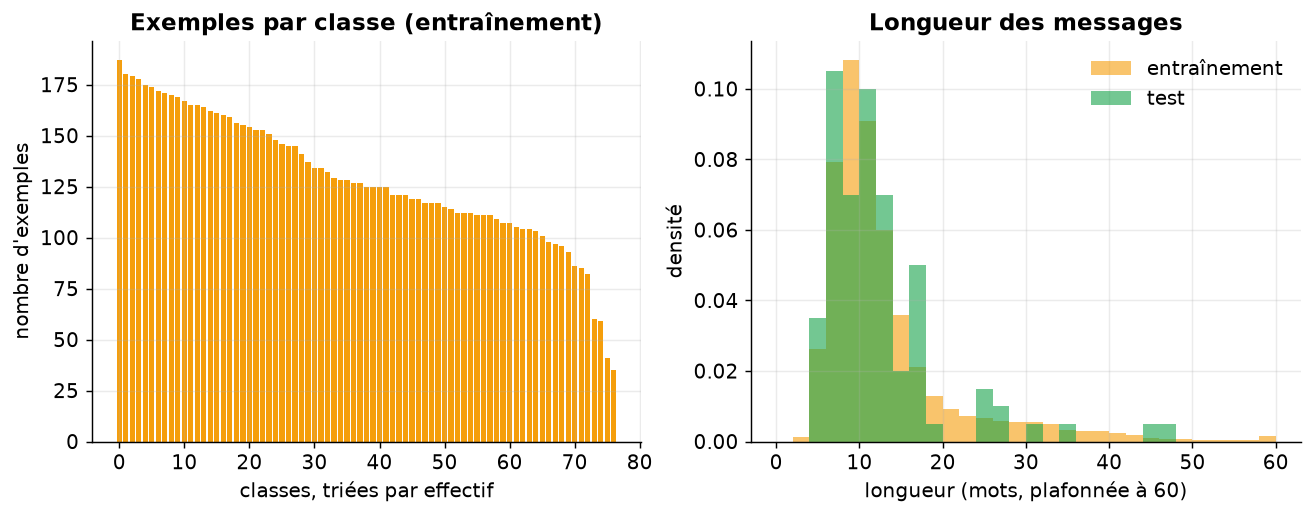

*Figure — À gauche, le nombre d'exemples d'entraînement par classe (une barre par classe) : une pente douce signale des classes à peu près équilibrées. À droite, la longueur des messages en mots, à l'entraînement et au test : des courbes proches signalent des parties comparables.*

,text,label
0,"Je souhaite un compte pour mes enfants, commen...",age_limit
1,Combien de temps faut-il pour que le transfert...,pending_transfer
2,Que dois-je faire pour transférer mon salaire ...,receiving_money
3,J'ai accidentellement effectué une transaction...,cancel_transfer
4,"Comment geler ma carte bancaire, suite à un re...",cash_withdrawal_not_recognised


In [9]:
if PHASE == "public":
    display(describe_splits({"train (pool)": train_pool, "calibration": calibration_df, "test": test_df}).round(1))
    plot_data_overview(train_pool, test_df, "data_overview")
preview(test_df, n=5) if PHASE == "public" else None

### Colonnes attendues et jeu factice

Sur les données internes, trois colonnes sont attendues : le texte anonymisé, la classe de routage et la **date de réception**, qui sert au découpage temporel. La cellule `PRIVATE_CONFIG` fait le lien avec les vrais noms de colonnes.

Pour vérifier que tout s'exécute sans rien exposer, on fabrique un **jeu factice** à partir de gabarits génériques, sans aucune donnée réelle : 12 motifs, 3 tournures par motif, puis des variations (jour, montant, formule de politesse, numéro de dossier).

In [10]:
PRIVATE_COLUMNS = {
    "text": "Texte du message client, anonymisé",
    "label": "Classe de routage annotée (motif ou sous-motif)",
    "received_at": "Date de réception pour le découpage temporel",
}
N_FAKE = 600  # taille du jeu factice : 50 messages par motif factice

# Gabarits factices et génériques : un motif = trois tournures.
FAKE_TEMPLATES = {
    "carte_bloquee": ["ma carte est bloquée depuis {day}", "carte de paiement refusée partout {day}, que faire ?", "je ne peux plus payer avec ma carte depuis {day}"],
    "opposition_carte": ["j'ai perdu ma carte {day}, je veux faire opposition", "on m'a volé ma carte {day}, bloquez-la svp", "comment faire opposition sur ma carte de paiement ?"],
    "virement_non_recu": ["mon virement de {amount} € n'est toujours pas arrivé", "le virement envoyé {day} n'apparaît pas sur le compte", "virement de {amount} euros introuvable"],
    "frais_inconnus": ["je ne comprends pas des frais de {amount} € sur mon compte", "pourquoi ai-je été prélevé de {amount} € de frais ?", "frais inconnus apparus {day}"],
    "plafond_paiement": ["je veux augmenter mon plafond de paiement à {amount} €", "plafond de carte atteint {day}, comment le relever ?", "mon paiement de {amount} € dépasse le plafond"],
    "changement_adresse": ["je viens de déménager, comment changer mon adresse ?", "mettre à jour mon adresse postale svp", "nouvelle adresse depuis {day}, merci de modifier"],
    "ouverture_compte": ["je souhaite ouvrir un compte", "quels documents pour ouvrir un compte joint ?", "ouverture de compte demandée {day}, où en est-on ?"],
    "cloture_compte": ["je veux clôturer mon compte", "fermeture de mon compte à prévoir rapidement", "comment fermer mon compte et récupérer {amount} € ?"],
    "litige_paiement": ["je conteste un paiement de {amount} € que je n'ai pas fait", "un commerçant m'a débité deux fois {amount} €", "paiement inconnu de {amount} € {day}"],
    "code_oublie": ["j'ai oublié mon code de carte", "code de carte bloqué après trois essais {day}", "comment recevoir un nouveau code confidentiel ?"],
    "retrait_refuse": ["le retrait de {amount} € a été refusé", "retrait impossible {day} alors que le solde est suffisant", "billets non distribués mais compte débité de {amount} €"],
    "releve_compte": ["où trouver mon relevé de compte du mois dernier ?", "je voudrais un relevé de compte depuis {day}", "envoyez-moi mes relevés de compte svp"],
}
FAKE_DAYS = ["hier", "ce matin", "lundi", "samedi soir", "la semaine dernière", "le 3 du mois", "vendredi"]
FAKE_OPENINGS = ["", "Bonjour, ", "Bonsoir, ", "Urgent : ", "Re: ", "bjr "]
FAKE_CLOSINGS = ["", " Merci.", " Cordialement.", " Merci de me rappeler.", " C'est urgent !"]

### Générateur de messages factices

`make_fake_data(n)` tire, pour chaque ligne, un motif, une tournure, des variations et une date de réception dans l'année. Le numéro de dossier, présent une fois sur deux, rend les doublons exacts rares, comme dans de vrais messages. Les lignes sont ensuite mélangées : le reste du code ne doit dépendre ni de leur ordre ni du nom des classes.

In [11]:
def make_fake_data(n: int) -> pd.DataFrame:
    """Fabrique `n` messages factices plausibles (aucune donnée réelle), aux colonnes attendues."""
    rng = random.Random(SEED)
    labels = list(FAKE_TEMPLATES)
    start = pd.Timestamp("2026-01-01 08:00")
    rows = []
    for i in range(n):
        label = labels[i % len(labels)]
        body = rng.choice(FAKE_TEMPLATES[label]).format(day=rng.choice(FAKE_DAYS), amount=rng.randint(5, 2500))
        reference = f" (dossier {rng.randint(1000, 99999)})" if rng.random() < 0.5 else ""
        rows.append({
            "text": rng.choice(FAKE_OPENINGS) + body + reference + rng.choice(FAKE_CLOSINGS),
            "label": label,
            "received_at": start + pd.Timedelta(minutes=rng.randint(0, 300 * 24 * 60)),
        })
    return pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)

### Préparation et découpage temporel

Le jeu interne, factice compris, est **relu depuis un fichier** : les types sont donc reconvertis explicitement (texte, classe, date). Puis :
- on retire les lignes vides et les **doublons exacts** ;
- on découpe **par date** : l'entraînement précède la calibration, qui précède le test, comme en production ;
- on retire du test et de la calibration les messages déjà vus à l'entraînement (à la casse près).

In [12]:
def prepare_private_data(raw: pd.DataFrame) -> pd.DataFrame:
    """Convertit les types, retire les lignes inutilisables et les doublons exacts."""
    frame = raw[list(PRIVATE_COLUMNS)].copy()
    frame["text"] = frame["text"].astype(str).str.strip()
    frame["label"] = frame["label"].astype(str).str.strip()
    frame["received_at"] = pd.to_datetime(frame["received_at"], errors="coerce", utc=True)
    usable = (frame["text"] != "") & (frame["text"].str.lower() != "nan") & frame["received_at"].notna()
    frame = frame[usable]
    deduplicated = frame.drop_duplicates(subset="text")
    print(f"{len(raw)} lignes lues, {len(frame)} utilisables, {len(frame) - len(deduplicated)} doublons exacts retirés")
    return deduplicated.reset_index(drop=True)


def temporal_split(frame: pd.DataFrame, n_test: int, n_calibration: int) -> tuple[pd.DataFrame, ...]:
    """Découpe par date : entraînement, puis calibration, puis test (les plus récents).

    Retour : (train, calibration, test), aux colonnes `text` et `label`.
    """
    frame = frame.sort_values("received_at", kind="stable").reset_index(drop=True)
    assert len(frame) >= n_test + n_calibration + 50, "jeu trop petit pour le découpage temporel"
    train = frame.iloc[: len(frame) - n_test - n_calibration]
    calibration = frame.iloc[len(frame) - n_test - n_calibration: len(frame) - n_test]
    test = frame.iloc[len(frame) - n_test:]
    seen = set(train["text"].str.lower())  # pas de message déjà vu à l'entraînement
    calibration = calibration[~calibration["text"].str.lower().isin(seen)]
    test = test[~test["text"].str.lower().isin(seen)]
    columns = ["text", "label"]
    return tuple(part[columns].reset_index(drop=True) for part in (train, calibration, test))

### Chargement des données internes

Cette cellule ne s'exécute qu'en phase `private`. On lit le jeu par `load_private_data` (jamais directement), puis on applique les mêmes contrôles et la même figure qu'en phase publique. Seuls des **agrégats** sont affichés, et `preview` ne montre que la structure du jeu.

In [13]:
if PHASE == "private":
    private_df = prepare_private_data(load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=N_FAKE))
    train_pool, calibration_df, test_df = temporal_split(private_df, N_TEST, N_CALIBRATION)
    display(describe_splits({"train (pool)": train_pool, "calibration": calibration_df, "test": test_df}).round(1))
    plot_data_overview(train_pool, test_df, "data_overview_private")
    if len(test_df) < 100:
        print("Attention : moins de 100 exemples de test après dédoublonnage, résultats peu fiables.")
preview(private_df) if PHASE == "private" else None

### Préparation commune aux deux phases

À partir d'ici, le code est le même quelle que soit la phase. Les **classes** sont déduites des données. Puis on tire :
- le jeu d'entraînement de CamemBERT (tout le reste du train à l'échelle complète) ;
- un **sous-ensemble** de ce jeu pour l'adaptation LoRA du décideur.

Une classe présente au test mais absente de l'entraînement ne peut être prédite par aucune des deux approches : le tableau les compte.

In [14]:
classes = sorted(set(train_pool["label"]) | set(calibration_df["label"]) | set(test_df["label"]))
class_index = {name: position for position, name in enumerate(classes)}

if N_TRAIN_ENCODER is None or N_TRAIN_ENCODER >= len(train_pool):
    encoder_train_df = train_pool.reset_index(drop=True)
else:
    encoder_train_df = train_pool.sample(n=N_TRAIN_ENCODER, random_state=SEED).reset_index(drop=True)
# Le décideur s'entraîne sur un sous-ensemble du même jeu : jamais plus de données que la référence.
n_decider = min(N_TRAIN_DECIDER, len(encoder_train_df))
decider_train_df = encoder_train_df.sample(n=n_decider, random_state=SEED).reset_index(drop=True)
unseen_classes = sorted(set(test_df["label"]) - set(encoder_train_df["label"]))

pd.DataFrame({
    "classes": [len(classes)],
    "train CamemBERT": [len(encoder_train_df)],
    "train décideur": [len(decider_train_df)],
    "calibration": [len(calibration_df)],
    "test": [len(test_df)],
    "classes du test absentes du train": [len(unseen_classes)],
}, index=["effectifs"])

,classes,train CamemBERT,train décideur,calibration,test,classes du test absentes du train
effectifs,77,500,96,100,100,1


### Trois conditions de test : propre, fautes de frappe, transcription

Comme dans la source, on fabrique des **variantes qui gardent la même bonne réponse** :
- **fautes de frappe** : environ 10 % des mots d'au moins 3 lettres reçoivent une faute (inversion de deux lettres, lettre oubliée, touche voisine sur un clavier AZERTY, lettre doublée) ;
- **transcription** : tout en minuscules et sans ponctuation, comme la sortie d'une transcription automatique (`normalize_fr`).

Chaque message reçoit son propre générateur aléatoire, dérivé de la graine : le bruit est déterministe.

In [15]:
TYPO_RATE = 0.10  # part des mots (au moins 3 lettres) qui reçoivent une faute de frappe
AZERTY_ROWS = ["azertyuiop", "qsdfghjklm", "wxcvbn"]  # rangées d'un clavier français


def neighbor_key(char: str, rng: random.Random) -> str:
    """Touche voisine de `char` sur la même rangée du clavier (le caractère lui-même s'il en est absent)."""
    for row in AZERTY_ROWS:
        position = row.find(char.lower())
        if position >= 0:
            return rng.choice([row[j] for j in (position - 1, position + 1) if 0 <= j < len(row)])
    return char


def add_typos(text: str, rate: float, rng: random.Random) -> str:
    """Insère une faute (inversion, oubli, touche voisine, doublement) dans environ `rate` des mots."""
    words = text.split(" ")
    for index, word in enumerate(words):
        letters = [i for i, char in enumerate(word) if char.isalpha()]
        if len(letters) < 3 or rng.random() >= rate:
            continue
        i = rng.choice(letters[:-1])  # jamais la dernière lettre : l'inversion reste possible
        operation = rng.choice(["swap", "delete", "neighbor", "double"])
        if operation == "swap":
            words[index] = word[:i] + word[i + 1] + word[i] + word[i + 2:]
        elif operation == "delete":
            words[index] = word[:i] + word[i + 1:]
        elif operation == "neighbor":
            words[index] = word[:i] + neighbor_key(word[i], rng) + word[i + 1:]
        else:
            words[index] = word[:i] + word[i] + word[i:]
    return " ".join(words)


def like_transcript(text: str) -> str:
    """Tout en minuscules, sans ponctuation, comme une transcription automatique."""
    return normalize_fr(text)

### Construction des trois versions du test

On applique les deux bruits aux mêmes messages de test, puis on mesure la **part de mots réellement modifiés**. Elle doit tourner autour de 10 %, un peu moins parce que les mots courts sont épargnés.

In [16]:
def make_test_conditions(texts: list[str]) -> dict[str, list[str]]:
    """Trois versions de chaque message de test, à bonne réponse inchangée."""
    typos = [add_typos(text, TYPO_RATE, random.Random(SEED * 1_000_003 + i)) for i, text in enumerate(texts)]
    return {"clean": list(texts), "typos": typos, "lowercase": [like_transcript(text) for text in texts]}


test_texts = make_test_conditions(list(test_df["text"]))
changed_words = [
    np.mean([a != b for a, b in zip(clean.split(" "), noisy.split(" "))])
    for clean, noisy in zip(test_texts["clean"], test_texts["typos"])
]
print(f"Mots modifiés par les fautes de frappe : {np.mean(changed_words):.1%} en moyenne")
preview(pd.DataFrame(test_texts), n=3)

Mots modifiés par les fautes de frappe : 7.0% en moyenne


,clean,typos,lowercase
0,"Je souhaite un compte pour mes enfants, commen...","Je souhaite un compte pour mes enfants, commen...",je souhaite un compte pour mes enfants comment...
1,Combien de temps faut-il pour que le transfert...,Combien de temps faut-il pour que le transfert...,combien de temps faut-il pour que le transfert...
2,Que dois-je faire pour transférer mon salaire ...,Que dois-je faire pour transférer mon salaire ...,que dois-je faire pour transférer mon salaire ...


## 3. L'approche de référence

### Étape commune : présélection de 8 candidats

Les deux approches choisissent parmi les **mêmes 8 intentions candidates**. On les présélectionne avec un modèle d'embeddings multilingue : chaque message devient un vecteur, chaque classe est représentée par le **centroïde** (la moyenne) des vecteurs de ses exemples d'entraînement, et l'on garde les 8 classes dont le centroïde est le plus proche, au sens du cosinus.

Si la bonne classe manque parmi les 8, les deux approches se trompent forcément : le **rappel@8** est leur plafond commun.

In [17]:
from sentence_transformers import SentenceTransformer

EMBEDDING_MODEL_ID = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
TOP_K = min(8, len(classes))  # 8 options par question, comme au protocole
assert TOP_K >= 2, "il faut au moins deux classes"

embedder = SentenceTransformer(model_path(EMBEDDING_MODEL_ID), device=device())


def embed(texts) -> np.ndarray:
    """Vecteurs de norme 1 pour une liste de textes (produit scalaire = cosinus)."""
    return embedder.encode(list(texts), batch_size=64, normalize_embeddings=True,
                           show_progress_bar=False, convert_to_numpy=True)


def class_centroids(texts, labels) -> np.ndarray:
    """Centroïde normalisé de chaque classe ; ligne de NaN pour une classe sans exemple."""
    vectors = embed(texts)
    centroids = np.full((len(classes), vectors.shape[1]), np.nan, dtype=np.float32)
    label_ids = np.array([class_index[label] for label in labels])
    for class_id in np.unique(label_ids):
        mean = vectors[label_ids == class_id].mean(axis=0)
        centroids[class_id] = mean / np.linalg.norm(mean)
    return centroids


centroids = class_centroids(encoder_train_df["text"], encoder_train_df["label"])
print(f"Modèle d'embeddings : {EMBEDDING_MODEL_ID} | classes avec centroïde : "
      f"{int(np.isfinite(centroids[:, 0]).sum())}/{len(classes)}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10900.56it/s]

Modèle d'embeddings : sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 | classes avec centroïde : 76/77


### Candidats de chaque jeu d'évaluation

On présélectionne les candidats de la calibration et de chacune des trois conditions de test. Le bruit change le texte, donc il peut aussi changer les candidats, comme il le ferait en production. On mélange ensuite l'ordre des 8 candidats, avec une graine : la lettre A ne doit pas toujours désigner la classe la plus proche.

Le tableau donne le rappel@8 et l'exactitude d'une **baseline de similarité**, qui retient simplement le candidat le plus proche.

In [18]:
def retrieve_candidates(texts) -> np.ndarray:
    """Indices des TOP_K classes les plus proches de chaque texte, par similarité décroissante."""
    scores = embed(texts) @ np.nan_to_num(centroids, nan=0.0).T
    scores[:, ~np.isfinite(centroids[:, 0])] = -np.inf  # une classe sans exemple n'est jamais candidate
    return np.argsort(-scores, axis=1, kind="stable")[:, :TOP_K]


def shuffle_rows(rows: np.ndarray, seed: int) -> np.ndarray:
    """Mélange l'ordre des candidats de chaque ligne (graine fixée)."""
    rng = np.random.default_rng(seed)
    return np.array([row[rng.permutation(len(row))] for row in rows])


EVAL_SETS = {"calibration": list(calibration_df["text"]), **test_texts}
gold = {
    name: np.array([class_index[label] for label in (calibration_df["label"] if name == "calibration" else test_df["label"])])
    for name in EVAL_SETS
}
ranked = {name: retrieve_candidates(texts) for name, texts in EVAL_SETS.items()}
candidates = {name: shuffle_rows(rows, SEED + i) for i, (name, rows) in enumerate(ranked.items())}

retrieval_table = pd.DataFrame({
    name: {
        f"rappel@{TOP_K}": float(np.mean((ranked[name] == gold[name][:, None]).any(axis=1))),
        "baseline similarité (top-1)": float(np.mean(ranked[name][:, 0] == gold[name])),
    }
    for name in EVAL_SETS
}).T
retrieval_table.round(3)

,rappel@8,baseline similarité (top-1)
calibration,0.94,0.61
clean,0.85,0.60
typos,0.85,0.59
lowercase,0.83,0.56


### CamemBERT : réglages et longueur des entrées

La référence est un **CamemBERT-base fine-tuné** sur toutes les classes, avec des réglages classiques : 3 époques, taux d'apprentissage $3\cdot10^{-5}$, lots de 32, montée progressive du taux sur 10 % des pas, précision mixte sur GPU.

Avant tout entraînement, on mesure la longueur des messages en **tokens** (les morceaux de mots que lit le modèle) et la part qui dépasserait le plafond : une entrée coupée peut perdre l'indice décisif.

In [19]:
import contextlib
import gc
import time

import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

ENCODER_MODEL_ID = "almanach/camembert-base"
ENCODER_EPOCHS = by_scale(reduced=1, full=3)  # 3 époques : réglage classique d'un fine-tuning complet
ENCODER_LEARNING_RATE = 3e-5  # taux d'apprentissage habituel pour un encodeur de taille base
ENCODER_BATCH_SIZE = 32  # exemples par pas de gradient
ENCODER_MAX_LENGTH = 128  # plafond en tokens, largement au-dessus des messages courts
WARMUP_RATIO = 0.1  # 10 % des pas en montée progressive du taux d'apprentissage
USE_FP16 = device() == "cuda"  # précision mixte seulement sur GPU NVIDIA
N_LATENCY = 15  # messages traités un par un pour mesurer la latence


def amp_context():
    """Contexte de calcul : float16 mixte sur GPU NVIDIA, float32 sinon."""
    return torch.autocast(device_type="cuda", dtype=torch.float16) if USE_FP16 else contextlib.nullcontext()


def free_memory() -> None:
    """Libère la mémoire entre deux modèles (RAM et GPU)."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


encoder_tokenizer = AutoTokenizer.from_pretrained(model_path(ENCODER_MODEL_ID))
all_texts = list(encoder_train_df["text"]) + [text for texts in EVAL_SETS.values() for text in texts]
token_counts = np.array([len(ids) for ids in encoder_tokenizer(all_texts)["input_ids"]])
cut_by_class = pd.Series(token_counts[: len(encoder_train_df)] > ENCODER_MAX_LENGTH).groupby(
    encoder_train_df["label"].values).mean()
print(f"Tokens CamemBERT : médiane {np.median(token_counts):.0f}, p95 {np.percentile(token_counts, 95):.0f}, "
      f"max {token_counts.max()} | coupées à {ENCODER_MAX_LENGTH} : {np.mean(token_counts > ENCODER_MAX_LENGTH):.2%} "
      f"(pire classe : {cut_by_class.max():.1%})")

Tokens CamemBERT : médiane 16, p95 43, max 101 | coupées à 128 : 0.00% (pire classe : 0.0%)


### Fonction d'entraînement de la référence

Une boucle PyTorch explicite, plus lisible et plus stable d'une version à l'autre que `Trainer` :
- mélange des exemples à chaque époque, avec la graine ;
- **AdamW** avec décroissance linéaire du taux d'apprentissage ;
- **précision mixte** float16 sur GPU : un `GradScaler` met la perte à l'échelle pour que les petits gradients ne s'annulent pas ;
- écrêtage des gradients à 1, pour éviter un pas trop brutal en début d'entraînement.

In [20]:
def train_encoder(texts: list[str], labels: list[str]):
    """Fine-tune CamemBERT-base sur toutes les classes ; rend le modèle entraîné, en mode évaluation."""
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_path(ENCODER_MODEL_ID), num_labels=len(classes)).to(device())
    targets = torch.tensor([class_index[label] for label in labels])
    total_steps = ENCODER_EPOCHS * math.ceil(len(texts) / ENCODER_BATCH_SIZE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=ENCODER_LEARNING_RATE, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)
    order_rng = np.random.default_rng(SEED)
    model.train()
    for epoch in range(ENCODER_EPOCHS):
        order, losses = order_rng.permutation(len(texts)), []
        for start in range(0, len(texts), ENCODER_BATCH_SIZE):
            batch = order[start:start + ENCODER_BATCH_SIZE]
            inputs = encoder_tokenizer([texts[i] for i in batch], padding=True, truncation=True,
                                       max_length=ENCODER_MAX_LENGTH, return_tensors="pt").to(device())
            with amp_context():
                loss = model(**inputs, labels=targets[torch.as_tensor(batch)].to(device())).loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
            losses.append(loss.item())
        print(f"  époque {epoch + 1}/{ENCODER_EPOCHS} : perte moyenne {np.mean(losses):.3f} "
              f"(hasard : ln({len(classes)}) = {np.log(len(classes)):.2f})")
    return model.eval()

### Entraînement de CamemBERT

On entraîne la référence sur son jeu complet (hors calibration). La perte est comparée au niveau du **hasard**, $\ln(\text{nombre de classes})$ : une perte qui reste à ce niveau signale un modèle qui n'a rien appris.

In [21]:
encoder_started = time.perf_counter()
encoder_model = train_encoder(list(encoder_train_df["text"]), list(encoder_train_df["label"]))
n_parameters = sum(p.numel() for p in encoder_model.parameters()) / 1e6
print(f"Modèle évalué : {ENCODER_MODEL_ID} ({n_parameters:.0f} M paramètres) | "
      f"entraînement : {time.perf_counter() - encoder_started:.0f} s sur {device()}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 10447.58it/s]


[transformers] CamembertForSequenceClassification LOAD REPORT from: almanach/camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  époque 1/1 : perte moyenne 4.342 (hasard : ln(77) = 4.34)
Modèle évalué : almanach/camembert-base (111 M paramètres) | entraînement : 88 s sur cpu


### Inférence de la référence, restreinte aux candidats

CamemBERT produit un **logit** (un score avant normalisation) pour chacune des classes. Pour comparer à périmètre égal, on ne garde que les logits des 8 candidats, dans l'ordre mélangé, puis le softmax les transforme en probabilités. On vérifie d'abord l'appel sur un exemple réel, puis on mesure la **latence** message par message, présélection comprise.

In [22]:
@torch.no_grad()
def encoder_logits(model, texts: list[str], batch_size: int = 64) -> np.ndarray:
    """Logits de CamemBERT sur toutes les classes, par lots, sans gradient."""
    model.eval()
    outputs = []
    for start in range(0, len(texts), batch_size):
        inputs = encoder_tokenizer(texts[start:start + batch_size], padding=True, truncation=True,
                                   max_length=ENCODER_MAX_LENGTH, return_tensors="pt").to(device())
        with amp_context():
            outputs.append(model(**inputs).logits.float().cpu().numpy())
    return np.concatenate(outputs)


check_logits = encoder_logits(encoder_model, test_texts["clean"][:1])
assert check_logits.shape == (1, len(classes)) and np.isfinite(check_logits).all()
if PHASE == "public":
    print(f"Contrôle : « {test_texts['clean'][0]} » -> {classes[int(check_logits.argmax())]} "
          f"(attendu : {test_df['label'].iloc[0]})")

encoder_full_logits = {name: encoder_logits(encoder_model, texts) for name, texts in EVAL_SETS.items()}
# Restriction aux mêmes candidats que le décideur : comparaison à périmètre égal
encoder_logits_by_set = {name: np.take_along_axis(full, candidates[name], axis=1)
                         for name, full in encoder_full_logits.items()}

encoder_latencies = []
for text in test_texts["clean"][:N_LATENCY]:
    with timer(encoder_latencies):
        row = retrieve_candidates([text])
        restricted = np.take_along_axis(encoder_logits(encoder_model, [text]), row, axis=1)
del encoder_model
free_memory()
pd.DataFrame([latency_stats(encoder_latencies)], index=["CamemBERT (ms par message)"]).round(1)

Contrôle : « Je souhaite un compte pour mes enfants, comment faire ? » -> failed_transfer (attendu : age_limit)


,p50,p95,n
CamemBERT (ms par message),55.7,99.6,15


## 4. La nouvelle approche

### Principe repris de la source, et écarts

Ce qui est repris de la section « comment ça marche » de l'étude d'audit :
- **état + question typée Choice** : le message est l'état, les K options sont déclarées dans la question ;
- **une seule passe**, sans génération : une probabilité par option déclarée ;
- **validation de la sortie** (étape 4) : options attendues, probabilités de somme 1 ;
- **perturbations à réponse constante** (étape 2) : 10 % de fautes de frappe, minuscules sans ponctuation ;
- **calibration** (étape 5) : ECE et recalibrage par température, comme le 0,213 → 0,042 rapporté pour le plus petit modèle.

Écarts assumés :
- pas de modèle de décision du commerce : Qwen3-0.6B est **adapté par LoRA** (de petites matrices ajoutées et entraînées, le reste du modèle restant figé) pour se comporter en décideur ;
- la probabilité se lit dans les logits des lettres au premier token. Mécaniquement, c'est proche de la variante « premier token » que la source réserve au LLM génératif, mais ici le modèle est entraîné à la tâche ;
- 8 options présélectionnées au lieu de toutes les classes ; ni questions Score ou Noul, ni questions groupées, ni explications S1-SHAP.

### Réglages du décideur et tokens des lettres

Les réglages LoRA suivent le plan : rang 16 sur les projections d'attention, une époque. On place le **remplissage à gauche** pour que la dernière position de chaque ligne soit toujours celle où se lit la réponse. Chaque lettre (« A », précédée d'un espace) doit correspondre à **un seul token** : sinon, le logit lu ne représenterait pas l'option entière.

In [23]:
import inspect

import peft
import transformers
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM

DECIDER_MODEL_ID = "Qwen/Qwen3-0.6B"
LETTERS = "ABCDEFGH"[:TOP_K]  # une lettre par option déclarée
LORA_RANK = 16  # rang des matrices LoRA
LORA_ALPHA = 32  # facteur d'échelle LoRA (deux fois le rang, usage courant)
LORA_DROPOUT = 0.05  # légère régularisation des adaptateurs
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj"]  # projections d'attention, comme au plan
DECIDER_LEARNING_RATE = 2e-4  # taux usuel pour LoRA, plus élevé qu'en fine-tuning complet
DECIDER_EPOCHS = 1  # une seule passe sur le sous-ensemble d'entraînement
DECIDER_BATCH_SIZE = by_scale(reduced=4, full=8)  # exemples par pas de gradient
INFERENCE_BATCH_SIZE = by_scale(reduced=8, full=32)  # prompts par passe à l'évaluation
MAX_MESSAGE_TOKENS = 96  # plafond du message dans le prompt (tokens Qwen)
LOG_EVERY = by_scale(reduced=6, full=25)  # fréquence des relevés de progression (en pas)
PROMPT_TEMPLATE = "Message client : {text}\nIntentions possibles :\n{options}\nRéponse :"

decider_tokenizer = AutoTokenizer.from_pretrained(model_path(DECIDER_MODEL_ID))
decider_tokenizer.padding_side = "left"  # la dernière position de chaque ligne est celle de la réponse
if decider_tokenizer.pad_token is None:
    decider_tokenizer.pad_token = decider_tokenizer.eos_token
letter_ids_per_option = [decider_tokenizer.encode(" " + letter, add_special_tokens=False) for letter in LETTERS]
assert all(len(ids) == 1 for ids in letter_ids_per_option), "chaque lettre doit être un seul token"
LETTER_IDS = [ids[0] for ids in letter_ids_per_option]
print("Tokens des options :", dict(zip(LETTERS, LETTER_IDS)))

Tokens des options : {'A': 362, 'B': 425, 'C': 356, 'D': 422, 'E': 468, 'F': 434, 'G': 479, 'H': 472}


### Mise en forme : état + question à options lettrées

Chaque message devient un prompt : le message, puis les 8 intentions candidates (leurs noms, tirets bas remplacés par des espaces), une par lettre, puis « Réponse : ». Un message trop long serait coupé à 96 tokens : on affiche la part concernée, qui doit rester proche de zéro.

In [24]:
def shorten_message(text: str) -> tuple[str, bool]:
    """Coupe le message à MAX_MESSAGE_TOKENS tokens ; indique aussi s'il a été coupé."""
    ids = decider_tokenizer.encode(text, add_special_tokens=False)
    if len(ids) <= MAX_MESSAGE_TOKENS:
        return text, False
    return decider_tokenizer.decode(ids[:MAX_MESSAGE_TOKENS]), True


def build_prompts(texts: list[str], candidate_rows: np.ndarray) -> tuple[list[str], float]:
    """Met chaque message sous la forme état + question Choice à options lettrées.

    Retour : la liste des prompts et la part des messages coupés.
    """
    prompts, n_cut = [], 0
    for text, row in zip(texts, candidate_rows):
        message, was_cut = shorten_message(text)
        options = "\n".join(f"{letter}. {classes[c].replace('_', ' ')}" for letter, c in zip(LETTERS, row))
        prompts.append(PROMPT_TEMPLATE.format(text=message, options=options))
        n_cut += int(was_cut)
    return prompts, n_cut / max(len(texts), 1)


decider_prompts, cut_shares = {}, {}
for name, texts in EVAL_SETS.items():
    decider_prompts[name], cut_shares[name] = build_prompts(texts, candidates[name])
prompt_lengths = np.array([len(decider_tokenizer.encode(p)) for prompts in decider_prompts.values() for p in prompts])
print(f"Prompts : médiane {np.median(prompt_lengths):.0f} tokens, max {prompt_lengths.max()} | "
      f"messages coupés : {max(cut_shares.values()):.2%} (pire jeu)")
if PHASE == "public":
    print("\nExemple de prompt :\n" + decider_prompts["clean"][0])

Prompts : médiane 78 tokens, max 155 | messages coupés : 0.00% (pire jeu)

Exemple de prompt :
Message client : Je souhaite un compte pour mes enfants, comment faire ?
Intentions possibles :
A. getting spare card
B. supported cards and currencies
C. cancel transfer
D. declined transfer
E. transfer into account
F. terminate account
G. age limit
H. top up by cash or cheque
Réponse :


### Exemples d'entraînement du décideur

À l'entraînement, la bonne classe doit figurer parmi les options. Si la présélection l'a manquée, elle remplace le candidat le moins proche. L'ordre des options est ensuite **mélangé** : la position de la bonne lettre doit être à peu près uniforme, sinon le modèle apprendrait une préférence pour une lettre plutôt que le sens.

In [25]:
def training_candidates(texts: list[str], labels: list[str]) -> tuple[np.ndarray, np.ndarray]:
    """Candidats d'entraînement : bonne classe forcée parmi les K, puis ordre mélangé.

    Retour : les candidats (n, K) et la position de la bonne lettre pour chaque exemple.
    """
    rng = np.random.default_rng(SEED)
    rows, targets = [], []
    for row, gold_id in zip(retrieve_candidates(texts), [class_index[label] for label in labels]):
        row = row.copy()
        if gold_id not in row:
            row[-1] = gold_id  # remplace le candidat le moins proche
        row = row[rng.permutation(len(row))]
        rows.append(row)
        targets.append(int(np.flatnonzero(row == gold_id)[0]))
    return np.array(rows), np.array(targets)


decider_train_rows, decider_train_targets = training_candidates(
    list(decider_train_df["text"]), list(decider_train_df["label"]))
decider_train_prompts, _ = build_prompts(list(decider_train_df["text"]), decider_train_rows)
print(f"{len(decider_train_prompts)} prompts d'entraînement ; bonne lettre par position :",
      dict(zip(LETTERS, np.bincount(decider_train_targets, minlength=TOP_K).tolist())))

96 prompts d'entraînement ; bonne lettre par position : {'A': 14, 'B': 10, 'C': 13, 'D': 7, 'E': 17, 'F': 9, 'G': 13, 'H': 13}


### Chargement de Qwen3-0.6B et ajout des adaptateurs LoRA

Les poids sont convertis en float32, qui servent de **poids maîtres**. Sur GPU, les calculs passent en float16 par la précision mixte. Le tableau affiche ce qui tourne vraiment :
- l'implémentation de l'attention ;
- le type des poids ;
- le calcul des logits sur la seule dernière position (argument `logits_to_keep`), s'il est disponible : le résultat est identique, pour un coût moindre ;
- la part de paramètres entraînables.

Deux `assert` contrôlent ce qui changerait la mesure.

In [26]:
LAST_POSITION_ARGUMENT = "logits_to_keep"  # argument de transformers : logits de la seule dernière position

set_seed(SEED)
base_model = AutoModelForCausalLM.from_pretrained(model_path(DECIDER_MODEL_ID)).to(device=device(), dtype=torch.float32)
keeps_last_position = LAST_POSITION_ARGUMENT in inspect.signature(base_model.forward).parameters
LOGITS_KWARGS = {LAST_POSITION_ARGUMENT: 1} if keeps_last_position else {}
lora_config = LoraConfig(r=LORA_RANK, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                         target_modules=LORA_TARGETS, task_type="CAUSAL_LM")
decider_model = get_peft_model(base_model, lora_config)
trainable = sum(p.numel() for p in decider_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in decider_model.parameters())

assert next(base_model.parameters()).dtype == torch.float32, "poids maîtres attendus en float32"
assert 0 < trainable < 0.05 * total, "seuls les adaptateurs LoRA doivent être entraînables"
decider_runtime = {
    "modèle": DECIDER_MODEL_ID,
    "matériel": device(),
    "attention": str(getattr(base_model.config, "_attn_implementation", "inconnue")),
    "poids": str(next(base_model.parameters()).dtype),
    "précision mixte fp16": USE_FP16,
    "logits de la seule dernière position": keeps_last_position,
    "paramètres entraînables": f"{trainable / 1e6:.2f} M sur {total / 1e6:.0f} M",
    "transformers / peft": f"{transformers.__version__} / {peft.__version__}",
}
pd.Series(decider_runtime, name="décideur").to_frame()

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 10089.40it/s]

,décideur
modèle,Qwen/Qwen3-0.6B
matériel,cpu
attention,sdpa
poids,torch.float32
précision mixte fp16,False
logits de la seule dernière position,True
paramètres entraînables,4.59 M sur 601 M
transformers / peft,5.22.2 / 0.21.2


### Lecture des probabilités et entraînement LoRA

`letter_logits` fait **une seule passe** et lit, à la dernière position, les logits des K lettres. La probabilité d'une option est $p_k = e^{z_k} / \sum_j e^{z_j}$, calculée sur ces seules lettres.

L'entraînement minimise l'**entropie croisée** sur ces K lettres, c'est-à-dire $-\ln p_{\text{bonne lettre}}$. On optimise ainsi directement la distribution que l'on évalue, sans perte de langage superflue. Comme le remplissage est à gauche, les positions sont recalculées pour que les vrais tokens ne soient pas décalés.

In [27]:
def letter_logits(model, prompts: list[str]) -> torch.Tensor:
    """Logits des K lettres au premier token de réponse : une seule passe, aucune génération."""
    inputs = decider_tokenizer(prompts, padding=True, return_tensors="pt").to(device())
    position_ids = (inputs["attention_mask"].cumsum(dim=-1) - 1).clamp(min=0)
    with amp_context():
        output = model(input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"],
                       position_ids=position_ids, **LOGITS_KWARGS)
    return output.logits[:, -1, LETTER_IDS].float()


def train_decider(model, prompts: list[str], targets: np.ndarray) -> list[float]:
    """Entraîne les seuls poids LoRA par entropie croisée sur les K lettres ; rend la perte de chaque pas."""
    set_seed(SEED)
    parameters = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(parameters, lr=DECIDER_LEARNING_RATE)
    total_steps = DECIDER_EPOCHS * math.ceil(len(prompts) / DECIDER_BATCH_SIZE)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)
    order_rng, losses, started = np.random.default_rng(SEED), [], time.perf_counter()
    model.train()
    for _ in range(DECIDER_EPOCHS):
        order = order_rng.permutation(len(prompts))
        for start in range(0, len(prompts), DECIDER_BATCH_SIZE):
            batch = order[start:start + DECIDER_BATCH_SIZE]
            logits = letter_logits(model, [prompts[i] for i in batch])
            loss = torch.nn.functional.cross_entropy(logits, torch.as_tensor(targets[batch], device=device()))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(parameters, 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
            losses.append(loss.item())
            if len(losses) % LOG_EVERY == 0:
                print(f"  pas {len(losses)}/{total_steps} : perte {np.mean(losses[-LOG_EVERY:]):.3f}, "
                      f"{time.perf_counter() - started:.0f} s écoulées")
    model.eval()
    return losses

### Adaptation LoRA

Une époque sur le sous-ensemble d'entraînement, avec un relevé régulier de la perte et du temps écoulé. Au hasard, la perte vaut $\ln K$ (environ 2,08 pour 8 options) : elle doit descendre nettement en dessous.

In [28]:
decider_started = time.perf_counter()
decider_losses = train_decider(decider_model, decider_train_prompts, decider_train_targets)
print(f"Entraînement LoRA : {time.perf_counter() - decider_started:.0f} s | perte finale (moyenne des "
      f"{min(10, len(decider_losses))} derniers pas) {np.mean(decider_losses[-10:]):.3f}, "
      f"contre ln(K) = {np.log(TOP_K):.3f} au hasard")

  pas 6/24 : perte 1.600, 28 s écoulées


  pas 12/24 : perte 1.865, 54 s écoulées


  pas 18/24 : perte 1.641, 78 s écoulées


  pas 24/24 : perte 1.831, 103 s écoulées
Entraînement LoRA : 103 s | perte finale (moyenne des 10 derniers pas) 1.813, contre ln(K) = 2.079 au hasard


### Inférence sur la calibration et les trois conditions de test

Les prompts sont **triés par longueur** avant d'être regroupés en lots. Le remplissage est ainsi réduit, puis l'ordre d'origine est rétabli. Une ligne de logits non finis (débordement numérique, par exemple) est une **sortie illisible** : elle est remplacée par une distribution uniforme, ce qui la compte comme une réponse peu sûre et le plus souvent fausse, et son taux est rapporté.

In [29]:
@torch.no_grad()
def decider_logits(prompts: list[str]) -> np.ndarray:
    """Logits des lettres pour une liste de prompts, par lots triés par longueur."""
    decider_model.eval()
    order = np.argsort([len(p) for p in prompts], kind="stable")
    outputs, started = [], time.perf_counter()
    for batch_number, start in enumerate(range(0, len(prompts), INFERENCE_BATCH_SIZE), start=1):
        batch = [prompts[i] for i in order[start:start + INFERENCE_BATCH_SIZE]]
        outputs.append(letter_logits(decider_model, batch).cpu().numpy())
        if batch_number % 10 == 0:
            done = min(start + INFERENCE_BATCH_SIZE, len(prompts))
            print(f"  {done}/{len(prompts)} prompts, {done / (time.perf_counter() - started):.1f} prompts/s")
    result = np.empty((len(prompts), TOP_K), dtype=np.float32)
    result[order] = np.concatenate(outputs)
    return result


decider_logits_by_set, invalid_shares = {}, {}
for name, prompts in decider_prompts.items():
    logits = decider_logits(prompts)
    unreadable = ~np.isfinite(logits).all(axis=1)
    logits[unreadable] = 0.0  # sortie illisible -> distribution uniforme
    decider_logits_by_set[name], invalid_shares[name] = logits, float(unreadable.mean())
    print(f"{name} : {len(prompts)} prompts, sorties illisibles {invalid_shares[name]:.1%}")

  80/100 prompts, 2.5 prompts/s


calibration : 100 prompts, sorties illisibles 0.0%


  80/100 prompts, 2.6 prompts/s


clean : 100 prompts, sorties illisibles 0.0%


  80/100 prompts, 2.6 prompts/s


typos : 100 prompts, sorties illisibles 0.0%


  80/100 prompts, 2.6 prompts/s


lowercase : 100 prompts, sorties illisibles 0.0%


### Contrôle sur un exemple réel et latence

On vérifie la sortie comme à l'étape 4 de la source : une probabilité par option attendue, de somme 1. On mesure ensuite la latence message par message, avec le même protocole que pour CamemBERT (présélection comprise), puis on libère la mémoire.

In [30]:
check_probabilities = torch.softmax(torch.from_numpy(decider_logits_by_set["clean"][:1]), dim=-1).numpy()[0]
assert check_probabilities.shape == (TOP_K,) and abs(check_probabilities.sum() - 1) < 1e-5
print(f"Modèle évalué : {DECIDER_MODEL_ID} + LoRA (r={LORA_RANK})")
if PHASE == "public":
    chosen = int(check_probabilities.argmax())
    print(f"Contrôle : lettre {LETTERS[chosen]} -> {classes[candidates['clean'][0][chosen]]} "
          f"(p = {check_probabilities[chosen]:.3f}, attendu : {test_df['label'].iloc[0]})")

decider_latencies = []
for text in test_texts["clean"][:N_LATENCY]:
    with timer(decider_latencies):
        row = retrieve_candidates([text])
        prompts, _ = build_prompts([text], row)
        with torch.no_grad():
            probabilities = torch.softmax(letter_logits(decider_model, prompts), dim=-1)
del decider_model, base_model
free_memory()
pd.DataFrame([latency_stats(decider_latencies)], index=["Décideur (ms par message)"]).round(1)

Modèle évalué : Qwen/Qwen3-0.6B + LoRA (r=16)
Contrôle : lettre E -> transfer_into_account (p = 0.433, attendu : age_limit)


,p50,p95,n
Décideur (ms par message),525.7,654.0,15


## 5. Évaluation

### Outils de mesure

La **réponse retenue** est l'option la plus probable, et sa **confiance** est sa probabilité.
- **ECE** : on range les réponses en 15 tranches de confiance, puis on fait la moyenne pondérée de l'écart entre confiance et taux de bonnes réponses, $\mathrm{ECE} = \sum_b \frac{n_b}{n}\,|\mathrm{acc}_b - \mathrm{conf}_b|$ ;
- **Brier** : $\sum_k (p_k - y_k)^2$ sur les K options, où $y_k = 1$ pour la bonne classe. Si celle-ci manque parmi les candidats, tous les $y_k$ valent 0 ;
- **température** : $p = \mathrm{softmax}(z / T)$. Un seul nombre $T$, ajusté sur la calibration propre, qui ne change jamais la réponse retenue.

Un message dont la bonne classe manque parmi les candidats n'a pas de « probabilité de la bonne classe ». On ajuste donc $T$ en minimisant la log-vraisemblance de la **justesse de la réponse retenue** : c'est précisément ce que mesure l'ECE.

In [31]:
from scipy.optimize import minimize_scalar
from scipy.stats import binomtest
from sklearn.metrics import f1_score

N_BINS = 15  # tranches de confiance de l'ECE, comme au protocole
NOISY_CONDITIONS = ["typos", "lowercase"]  # conditions regroupées pour les métriques sur texte bruité


def softmax(logits: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    """Probabilités par option à partir des logits, divisés par la température."""
    scaled = logits / temperature
    exponentials = np.exp(scaled - scaled.max(axis=1, keepdims=True))
    return exponentials / exponentials.sum(axis=1, keepdims=True)


def expected_calibration_error(correct, confidence, n_bins: int = N_BINS) -> float:
    """ECE à tranches de largeur égale : écart moyen pondéré entre confiance et justesse."""
    correct, confidence = np.asarray(correct, dtype=float), np.asarray(confidence, dtype=float)
    bins = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    gaps = [(bins == b).sum() * abs(correct[bins == b].mean() - confidence[bins == b].mean()) for b in np.unique(bins)]
    return float(np.sum(gaps) / len(correct))


def top_label(probabilities: np.ndarray, candidate_rows: np.ndarray, gold_ids: np.ndarray) -> dict:
    """Réponse retenue, sa confiance, sa justesse (0/1) et le score de Brier de chaque exemple."""
    predicted = candidate_rows[np.arange(len(candidate_rows)), probabilities.argmax(axis=1)]
    one_hot = (candidate_rows == gold_ids[:, None]).astype(float)
    return {"confidence": probabilities.max(axis=1), "predicted": predicted,
            "correct": (predicted == gold_ids).astype(float), "brier": ((probabilities - one_hot) ** 2).sum(axis=1)}


def fit_temperature(logits: np.ndarray, candidate_rows: np.ndarray, gold_ids: np.ndarray) -> float:
    """Température qui minimise la log-vraisemblance négative de la justesse de la réponse retenue."""
    def negative_log_likelihood(log_temperature: float) -> float:
        """Log-vraisemblance négative moyenne de la justesse, pour une température exp(log_temperature)."""
        out = top_label(softmax(logits, np.exp(log_temperature)), candidate_rows, gold_ids)
        confidence = np.clip(out["confidence"], 1e-6, 1 - 1e-6)
        return float(-np.mean(out["correct"] * np.log(confidence) + (1 - out["correct"]) * np.log(1 - confidence)))
    # On cherche log(T) entre -3 et 3, soit T entre 0,05 et 20 : T reste positive.
    return float(np.exp(minimize_scalar(negative_log_likelihood, bounds=(-3.0, 3.0), method="bounded").x))

### Recalibrage et évaluation des deux approches

Pour chaque approche, on ajuste la température sur le **lot de calibration propre uniquement**, puis on l'applique telle quelle aux trois conditions de test. C'est ce qui se passerait en production : on recalibre sur des données propres, puis on reçoit du texte bruité. Une température $T > 1$ signale un modèle **surconfiant** (on adoucit ses probabilités), $T < 1$ un modèle **sous-confiant**.

In [32]:
def evaluate_approach(logits_by_set: dict[str, np.ndarray]) -> dict:
    """Ajuste la température sur la calibration propre, puis évalue chaque condition de test.

    Retour : la température et, par condition, les sorties brutes et recalibrées.
    """
    temperature = fit_temperature(logits_by_set["calibration"], candidates["calibration"], gold["calibration"])
    details = {}
    for condition in test_texts:
        raw_probabilities = softmax(logits_by_set[condition])
        details[condition] = {
            "raw": top_label(raw_probabilities, candidates[condition], gold[condition]),
            "recalibrated": top_label(softmax(logits_by_set[condition], temperature),
                                      candidates[condition], gold[condition]),
            "raw_probabilities": raw_probabilities,
        }
    return {"temperature": temperature, "details": details}


reference_eval = evaluate_approach(encoder_logits_by_set)
new_eval = evaluate_approach(decider_logits_by_set)
pd.DataFrame({"température ajustée": [reference_eval["temperature"], new_eval["temperature"]]},
             index=["CamemBERT (référence)", "Décideur Qwen3 + LoRA"]).round(3)

,température ajustée
CamemBERT (référence),0.516
Décideur Qwen3 + LoRA,0.896


### Métriques et intervalles de confiance

Les métriques de calibration (ECE brute, ECE recalibrée, Brier recalibré) portent sur le **texte bruité**, les deux conditions regroupées. L'exactitude et le macro-F1 portent sur le **texte propre**. La baisse sous bruit, mesurée exemple par exemple, vaut exactitude propre moins exactitude bruitée moyenne.

Le **bootstrap** : on retire 1 000 fois des exemples au hasard, avec remise, pour voir à quel point chaque chiffre dépend de l'échantillon. Les 2,5 % et 97,5 % extrêmes bornent l'intervalle à 95 %.

In [33]:
def pooled(evaluation: dict, version: str, key: str) -> np.ndarray:
    """Concatène une sortie (`raw` ou `recalibrated`) sur les conditions bruitées."""
    return np.concatenate([evaluation["details"][c][version][key] for c in NOISY_CONDITIONS])


def metrics_with_ci(evaluation: dict) -> tuple[dict, dict]:
    """Valeur et intervalle de confiance à 95 % (bootstrap) de chaque métrique enregistrée."""
    details, clean = evaluation["details"], evaluation["details"]["clean"]["raw"]
    in_candidates = (candidates["clean"] == gold["clean"][:, None]).any(axis=1).astype(float)
    drop = clean["correct"] - np.mean([details[c]["raw"]["correct"] for c in NOISY_CONDITIONS], axis=0)
    mean = lambda values, _: float(np.mean(values))
    macro_f1 = lambda truth, predicted: float(f1_score(truth, predicted, average="macro", zero_division=0))
    estimates = {
        "expected_calibration_error": bootstrap_ci(pooled(evaluation, "raw", "correct"), pooled(evaluation, "raw", "confidence"), expected_calibration_error, seed=SEED),
        "expected_calibration_error_recalibrated": bootstrap_ci(pooled(evaluation, "recalibrated", "correct"), pooled(evaluation, "recalibrated", "confidence"), expected_calibration_error, seed=SEED),
        "brier_score": bootstrap_ci(pooled(evaluation, "recalibrated", "brier"), pooled(evaluation, "recalibrated", "brier"), mean, seed=SEED),
        "accuracy": bootstrap_ci(clean["correct"], clean["correct"], mean, seed=SEED),
        "macro_f1": bootstrap_ci(gold["clean"], clean["predicted"], macro_f1, seed=SEED),
        "accuracy_drop_under_noise": bootstrap_ci(drop, drop, mean, seed=SEED),
        "candidate_recall_at_8": bootstrap_ci(in_candidates, in_candidates, mean, seed=SEED),
    }
    metrics = {key: float(value[0]) for key, value in estimates.items()}
    ci95 = {key: [float(value[1]), float(value[2])] for key, value in estimates.items()}
    return metrics, ci95


reference_metrics, reference_ci = metrics_with_ci(reference_eval)
new_metrics, new_ci = metrics_with_ci(new_eval)
pd.DataFrame({"CamemBERT (référence)": reference_metrics, "Décideur Qwen3 + LoRA": new_metrics}).round(3)

,CamemBERT (référence),Décideur Qwen3 + LoRA
expected_calibration_error,0.014,0.140
expected_calibration_error_recalibrated,0.023,0.143
brier_score,0.756,0.549
accuracy,0.110,0.400
macro_f1,0.045,0.343
accuracy_drop_under_noise,-0.010,-0.025
candidate_recall_at_8,0.850,0.850


### Tests appariés

Les deux approches sont jugées sur **les mêmes exemples** : on peut donc les comparer exemple par exemple.
- **bootstrap apparié de l'ECE recalibrée** : à chaque tirage, les mêmes exemples pour les deux approches. On obtient un intervalle sur l'écart (nouvelle − référence) et sur le rapport des ECE ;
- **test de McNemar** sur texte propre : on ne regarde que les messages où une seule des deux approches se trompe. Si elles se valent, ces désaccords se partagent à 50/50.

In [34]:
PRIMARY = "expected_calibration_error_recalibrated"  # métrique principale du plan


def paired_ece_gap(n_resamples: int = 1000) -> tuple[np.ndarray, np.ndarray]:
    """Bootstrap apparié de l'ECE recalibrée sur texte bruité.

    Retour : IC à 95 % de l'écart (nouvelle − référence) et du rapport (nouvelle / référence).
    """
    ref_correct, ref_conf = pooled(reference_eval, "recalibrated", "correct"), pooled(reference_eval, "recalibrated", "confidence")
    new_correct, new_conf = pooled(new_eval, "recalibrated", "correct"), pooled(new_eval, "recalibrated", "confidence")
    rng = np.random.default_rng(SEED)
    gaps, ratios = [], []
    for _ in range(n_resamples):
        idx = rng.integers(0, len(ref_correct), len(ref_correct))
        ref_ece = expected_calibration_error(ref_correct[idx], ref_conf[idx])
        new_ece = expected_calibration_error(new_correct[idx], new_conf[idx])
        gaps.append(new_ece - ref_ece)
        ratios.append(new_ece / max(ref_ece, 1e-9))
    return np.percentile(gaps, [2.5, 97.5]), np.percentile(ratios, [2.5, 97.5])


gap_ci, ratio_ci = paired_ece_gap()
ref_clean = reference_eval["details"]["clean"]["raw"]["correct"]
new_clean = new_eval["details"]["clean"]["raw"]["correct"]
only_reference = int(((ref_clean == 1) & (new_clean == 0)).sum())
only_new = int(((ref_clean == 0) & (new_clean == 1)).sum())
disagreements = only_reference + only_new
mcnemar_p = binomtest(min(only_reference, only_new), disagreements, 0.5).pvalue if disagreements else 1.0
pd.DataFrame({
    "valeur": [f"[{gap_ci[0]:+.3f} ; {gap_ci[1]:+.3f}]", f"[{ratio_ci[0]:.2f} ; {ratio_ci[1]:.2f}]",
               f"{only_reference} / {only_new}", f"{mcnemar_p:.3g}"],
}, index=["IC 95 % écart d'ECE recalibrée (nouvelle − réf.)", "IC 95 % rapport d'ECE (nouvelle / réf.)",
          "juste seulement pour réf. / seulement pour nouvelle", "p-valeur McNemar (propre)"])

,valeur
IC 95 % écart d'ECE recalibrée (nouvelle − réf.),[+0.070 ; +0.185]
IC 95 % rapport d'ECE (nouvelle / réf.),[2.23 ; 27.14]
juste seulement pour réf. / seulement pour nouvelle,6 / 35
p-valeur McNemar (propre),4.87e-06


### Verdict sur l'hypothèse

Un piège à garder en tête : un prédicteur qui annoncerait toujours la même confiance, égale à son taux de réussite, aurait une ECE quasi nulle tout en étant inutile. La calibration ne vaut donc rien sans **exactitude**. D'où une condition d'éligibilité : la borne basse de l'intervalle de l'exactitude doit dépasser le **prédicteur trivial** (la classe majoritaire, ou le hasard). Le verdict vaut :
- **confirmée** : ECE recalibrée au moins 30 % plus basse, écart significatif, et perte d'exactitude d'au plus 3 points ;
- **infirmée** : décideur significativement moins bien calibré, ou perte de plus de 3 points, ou baisse de 30 % exclue par l'intervalle ;
- **non tranché** : sinon ; **non concluant** : si une approche n'est pas éligible.

In [35]:
HYPOTHESIS_REDUCTION = 0.30  # baisse relative d'ECE recalibrée visée par l'hypothèse
MAX_ACCURACY_LOSS = 0.03  # perte d'exactitude tolérée sur texte propre (3 points)

majority_rate = float(test_df["label"].value_counts(normalize=True).iloc[0])
trivial_rate = max(majority_rate, 1 / len(classes))
similarity_top1 = float(np.mean(ranked["clean"][:, 0] == gold["clean"]))
eligible = {"référence": reference_ci["accuracy"][0] > trivial_rate, "nouvelle": new_ci["accuracy"][0] > trivial_rate}
reduction = 1 - new_metrics[PRIMARY] / max(reference_metrics[PRIMARY], 1e-9)
accuracy_gap = new_metrics["accuracy"] - reference_metrics["accuracy"]

if not all(eligible.values()):
    verdict = "non concluant : au moins une approche ne dépasse pas le prédicteur trivial"
elif reduction >= HYPOTHESIS_REDUCTION and gap_ci[1] < 0 and accuracy_gap >= -MAX_ACCURACY_LOSS:
    verdict = "hypothèse confirmée"
elif gap_ci[0] > 0 or accuracy_gap < -MAX_ACCURACY_LOSS or ratio_ci[0] > 1 - HYPOTHESIS_REDUCTION:
    verdict = "hypothèse infirmée"
else:
    verdict = "non tranché : écart compatible avec les fluctuations d'échantillon"

pd.Series({
    "prédicteur trivial (exactitude)": f"{trivial_rate:.3f}",
    "baseline similarité top-1 (exactitude)": f"{similarity_top1:.3f}",
    "référence éligible / nouvelle éligible": f"{eligible['référence']} / {eligible['nouvelle']}",
    "baisse relative d'ECE recalibrée (bruité)": f"{reduction:+.1%}",
    "écart d'exactitude propre (nouvelle − réf.)": f"{accuracy_gap:+.3f}",
    "verdict": verdict,
}, name="bilan").to_frame()

,bilan
prédicteur trivial (exactitude),0.050
baseline similarité top-1 (exactitude),0.600
référence éligible / nouvelle éligible,False / True
baisse relative d'ECE recalibrée (bruité),-535.9%
écart d'exactitude propre (nouvelle − réf.),+0.290
verdict,non concluant : au moins une approche ne dépas...


### Enregistrement des résultats

Les métriques, leurs intervalles et les latences (médiane p50 et 95e centile p95, en millisecondes par message) sont écrits dans `results_<phase>.json`. Les notes gardent la trace de ce qui a tourné (modèles, effectifs, températures, taux de sorties illisibles, verdict).

In [36]:
METRIC_LABELS = {
    "expected_calibration_error": "ECE brute (bruité)",
    "expected_calibration_error_recalibrated": "ECE recalibrée (bruité)",
    "brier_score": "Brier recalibré (bruité)",
    "accuracy": "Exactitude (propre)",
    "macro_f1": "Macro-F1 (propre)",
    "accuracy_drop_under_noise": "Baisse d'exactitude sous bruit",
    "candidate_recall_at_8": "Rappel@8 des candidats",
}
latency = lambda durations: {key: float(value) for key, value in latency_stats(durations).items()}
results = save_results({
    "primary_metric": PRIMARY,
    "direction": "min",
    "metric_labels": METRIC_LABELS,
    "dataset": {"name": DATASET_ID if PHASE == "public" else "données internes",
                "config": "default" if PHASE == "public" else "private",
                "split": "test", "n_examples": int(len(test_df))},
    "approaches": [
        {"name": "CamemBERT-base fine-tuné", "role": "reference", "metrics": reference_metrics,
         "ci95": reference_ci, "latency_ms": latency(encoder_latencies),
         "notes": f"{ENCODER_MODEL_ID}, {len(encoder_train_df)} exemples, {ENCODER_EPOCHS} époque(s), "
                  f"softmax restreint aux {TOP_K} candidats, T = {reference_eval['temperature']:.3f}"},
        {"name": "Décideur typé Qwen3-0.6B + LoRA", "role": "new", "metrics": new_metrics,
         "ci95": new_ci, "latency_ms": latency(decider_latencies),
         "notes": f"{DECIDER_MODEL_ID} + LoRA r={LORA_RANK}, {len(decider_train_df)} exemples, "
                  f"T = {new_eval['temperature']:.3f}, sorties illisibles {max(invalid_shares.values()):.1%}, "
                  f"attention {decider_runtime['attention']}, verdict : {verdict}"},
    ],
})
results_table(results)

résultats enregistrés : results_public.json


,rôle,ECE brute (bruité),ECE recalibrée (bruité),Brier recalibré (bruité),Exactitude (propre),Macro-F1 (propre),Baisse d'exactitude sous bruit,Rappel@8 des candidats,latence p50 (ms)
approche,,,,,,,,,
CamemBERT-base fine-tuné,référence,0.01385 [0.006089 ; 0.06629],0.02251 [0.006672 ; 0.06761],0.7556 [0.7134 ; 0.7909],0.11 [0.05 ; 0.18],0.04468 [0.01639 ; 0.07264],-0.01 [-0.035 ; 0.015],0.85 [0.77 ; 0.92],55.72
Décideur typé Qwen3-0.6B + LoRA,nouvelle,0.1397 [0.1143 ; 0.2018],0.1432 [0.1069 ; 0.2043],0.5487 [0.4877 ; 0.6116],0.4 [0.31 ; 0.5],0.3426 [0.2312 ; 0.3797],-0.025 [-0.11 ; 0.065],0.85 [0.77 ; 0.92],525.66


### Figure de synthèse

Une barre par approche et par métrique, avec son intervalle à 95 %. Pour les trois métriques de calibration, plus bas vaut mieux. Pour l'exactitude, plus haut vaut mieux.

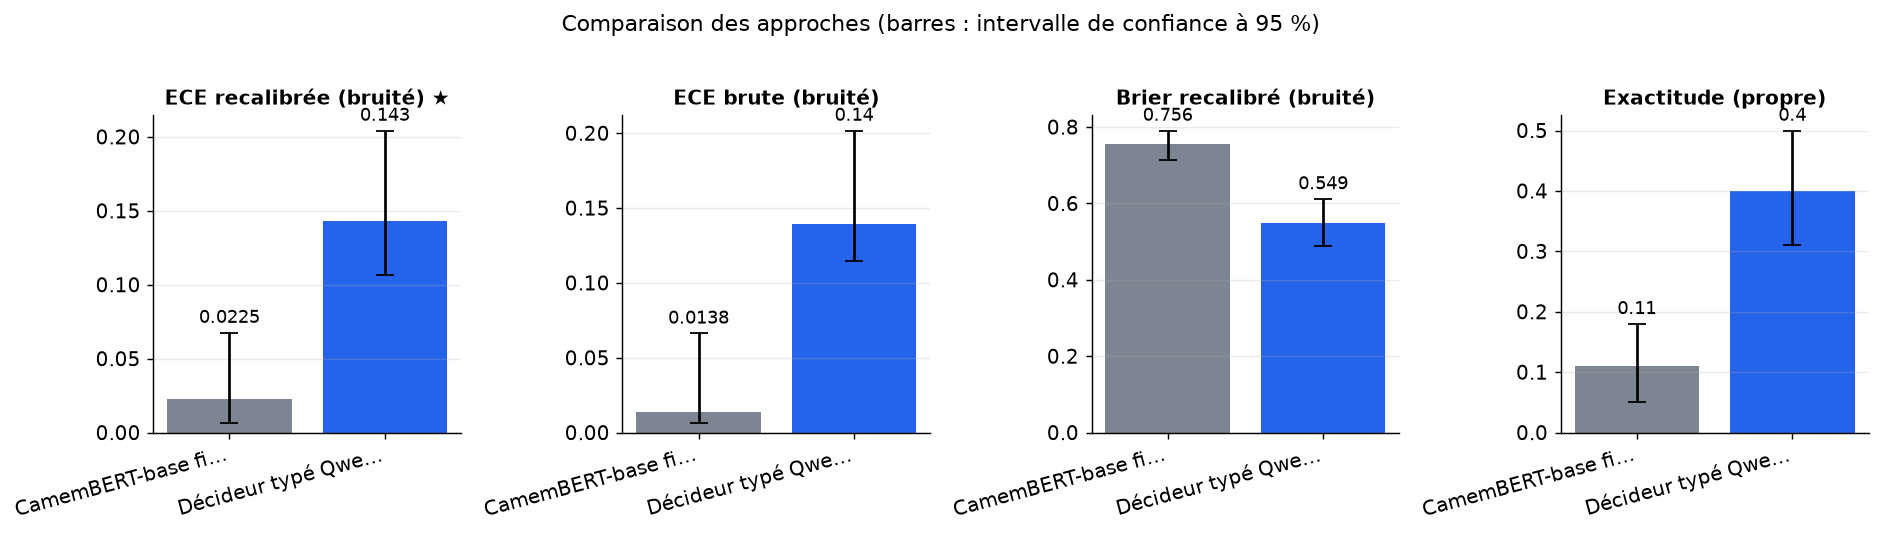

*Figure — Valeur de chaque métrique par approche (★ : métrique principale, à minimiser) ; les barres d'erreur donnent l'intervalle de confiance à 95 % sur 100 exemples de test.*

In [37]:
plot_comparison(results, metrics=[PRIMARY, "expected_calibration_error", "brier_score", "accuracy"])

## 6. Analyse des résultats

### D'où vient l'écart ? Détail par condition

On détaille l'exactitude et l'ECE de chaque condition, puis on ajoute une colonne inspirée de la source. Certains modèles de décision renvoient un champ « confidence » égal à **1 − entropie normalisée** de leur distribution, $1 - H(p)/\ln K$ : il mesure à quel point les probabilités sont concentrées, pas la chance d'avoir raison. Calculer l'ECE de ce score sur nos sorties montre ce qu'on perdrait à le prendre pour une probabilité. Pour situer CamemBERT, on rappelle aussi son exactitude sans restriction aux candidats.

In [38]:
APPROACHES = [("CamemBERT (référence)", reference_eval, COLORS["reference"]),
              ("Décideur Qwen3 + LoRA", new_eval, COLORS["new"])]
CONDITION_NAMES = {"clean": "propre", "typos": "fautes de frappe", "lowercase": "minuscules sans ponct."}


def entropy_confidence(probabilities: np.ndarray) -> np.ndarray:
    """Score « 1 − entropie normalisée » : concentration de la distribution, pas une probabilité."""
    entropy = -(probabilities * np.log(np.clip(probabilities, 1e-12, 1.0))).sum(axis=1)
    return 1 - entropy / np.log(probabilities.shape[1])


rows = []
for label, evaluation, _ in APPROACHES:
    for condition, name in CONDITION_NAMES.items():
        raw, recalibrated = evaluation["details"][condition]["raw"], evaluation["details"][condition]["recalibrated"]
        rows.append({
            "approche": label, "condition": name, "exactitude": raw["correct"].mean(),
            "ECE brute": expected_calibration_error(raw["correct"], raw["confidence"]),
            "ECE recalibrée": expected_calibration_error(recalibrated["correct"], recalibrated["confidence"]),
            "ECE de 1 − entropie norm.": expected_calibration_error(
                raw["correct"], entropy_confidence(evaluation["details"][condition]["raw_probabilities"])),
            "confiance moyenne (recal.)": recalibrated["confidence"].mean(),
        })
unrestricted_accuracy = float(np.mean(encoder_full_logits["clean"].argmax(axis=1) == gold["clean"]))
print(f"CamemBERT sans restriction aux candidats (propre) : exactitude {unrestricted_accuracy:.3f} "
      f"| restreint : {reference_metrics['accuracy']:.3f} | rappel@{TOP_K} : {new_metrics['candidate_recall_at_8']:.3f}")
pd.DataFrame(rows).set_index(["approche", "condition"]).round(3)

CamemBERT sans restriction aux candidats (propre) : exactitude 0.010 | restreint : 0.110 | rappel@8 : 0.850


exactitude  ECE brute  \
approche              condition                                       
CamemBERT (référence) propre                        0.11      0.054   
                      fautes de frappe              0.12      0.055   
                      minuscules sans ponct.        0.12      0.028   
Décideur Qwen3 + LoRA propre                        0.40      0.115   
                      fautes de frappe              0.38      0.233   
                      minuscules sans ponct.        0.47      0.129   

                                              ECE recalibrée  \
approche              condition                                
CamemBERT (référence) propre                           0.033   
                      fautes de frappe                 0.023   
                      minuscules sans ponct.           0.022   
Décideur Qwen3 + LoRA propre                           0.143   
                      fautes de frappe                 0.211   
                      minuscules sans ponct.           0.114   

                                              ECE de 1 − entropie norm.  \
approche              condition                                           
CamemBERT (référence) propre                                      0.110   
                      fautes de frappe                            0.120   
                      minuscules sans ponct.                      0.120   
Décideur Qwen3 + LoRA propre                                      0.133   
                      fautes de frappe                            0.202   
                      minuscules sans ponct.                      0.198   

                                              confiance moyenne (recal.)  
approche              condition                                           
CamemBERT (référence) propre                                       0.143  
                      fautes de frappe                             0.143  
                      minuscules sans ponct.                       0.142  
Décideur Qwen3 + LoRA propre                                       0.521  
                      fautes de frappe                             0.526  
                      minuscules sans ponct.                       0.517

### Diagramme de fiabilité sur texte bruité

On range les réponses en 10 tranches de confiance. Chaque point place la confiance moyenne d'une tranche (en abscisse) face à son taux réel de bonnes réponses (en ordonnée). Sur la diagonale, la calibration est parfaite. Sous la diagonale, le modèle est **surconfiant** : il annonce plus qu'il ne réussit. Les pointillés montrent les probabilités brutes, le trait plein les probabilités après température.

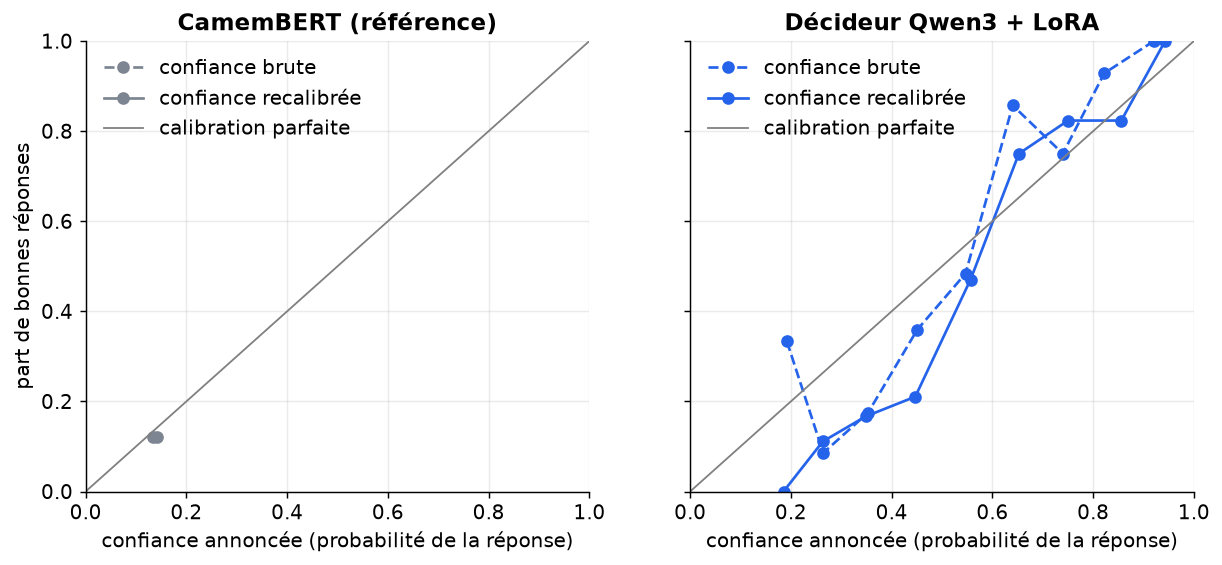

*Figure — Diagramme de fiabilité sur texte bruité (fautes de frappe et minuscules regroupées). Un point sous la diagonale signale une surconfiance ; le trait plein montre l'effet de la température.*

In [39]:
def reliability_curve(correct: np.ndarray, confidence: np.ndarray, n_bins: int = 10) -> tuple[np.ndarray, np.ndarray]:
    """Confiance moyenne et taux de bonnes réponses de chaque tranche non vide."""
    bins = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    kept = [b for b in range(n_bins) if (bins == b).any()]
    return (np.array([confidence[bins == b].mean() for b in kept]),
            np.array([correct[bins == b].mean() for b in kept]))


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (label, evaluation, color) in zip(axes, APPROACHES):
    for version, style, name in [("raw", "--", "brute"), ("recalibrated", "-", "recalibrée")]:
        x, y = reliability_curve(pooled(evaluation, version, "correct"), pooled(evaluation, version, "confidence"))
        ax.plot(x, y, style, marker="o", color=color, label=f"confiance {name}")
    ax.plot([0, 1], [0, 1], color="grey", linewidth=1, label="calibration parfaite")
    ax.set(title=label, xlabel="confiance annoncée (probabilité de la réponse)", xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left")
axes[0].set_ylabel("part de bonnes réponses")
save_figure(fig, "reliability_diagram",
            "Diagramme de fiabilité sur texte bruité (fautes de frappe et minuscules regroupées). "
            "Un point sous la diagonale signale une surconfiance ; le trait plein montre l'effet de la température.")

### Robustesse : exactitude et calibration selon la condition

Cette figure isole l'effet du bruit. Une barre qui baisse beaucoup entre « propre » et une condition bruitée signale un modèle sensible aux raccourcis de surface : orthographe exacte, majuscules, ponctuation. L'ECE recalibrée montre si la température, ajustée sur du texte propre, tient encore sur du texte bruité.

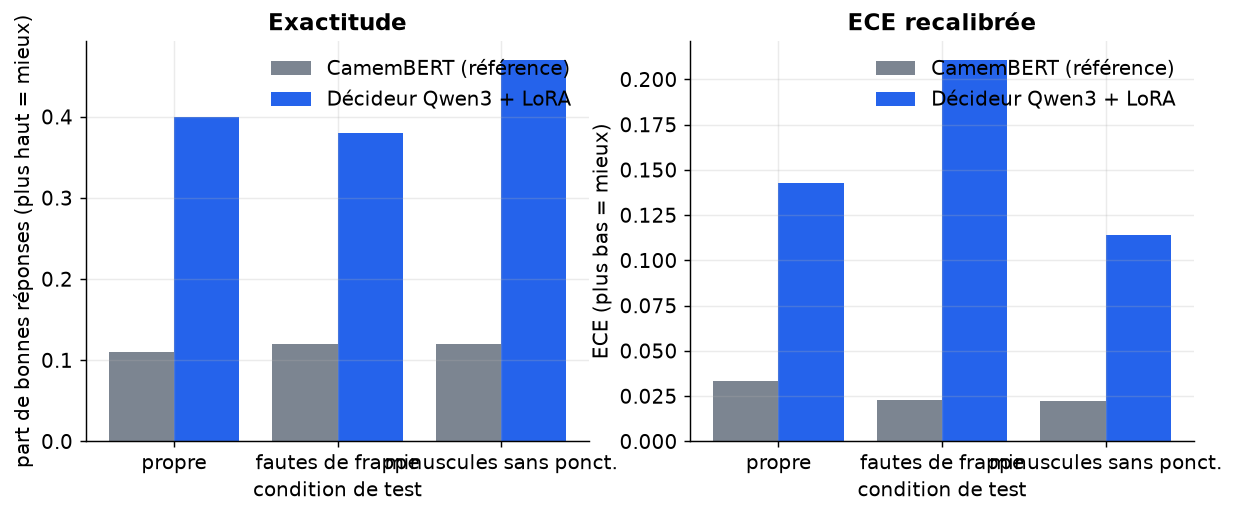

*Figure — Exactitude (à gauche) et ECE après température (à droite) pour chaque condition de test. La température est ajustée sur du texte propre puis appliquée telle quelle au texte bruité.*

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
positions = np.arange(len(CONDITION_NAMES))
for offset, (label, evaluation, color) in zip((-0.2, 0.2), APPROACHES):
    details = evaluation["details"]
    accuracy = [details[c]["raw"]["correct"].mean() for c in CONDITION_NAMES]
    ece = [expected_calibration_error(details[c]["recalibrated"]["correct"], details[c]["recalibrated"]["confidence"])
           for c in CONDITION_NAMES]
    axes[0].bar(positions + offset, accuracy, width=0.4, color=color, label=label)
    axes[1].bar(positions + offset, ece, width=0.4, color=color, label=label)
for ax, title, ylabel in zip(axes, ["Exactitude", "ECE recalibrée"],
                             ["part de bonnes réponses (plus haut = mieux)", "ECE (plus bas = mieux)"]):
    ax.set_xticks(positions, list(CONDITION_NAMES.values()))
    ax.set(title=title, xlabel="condition de test", ylabel=ylabel)
    ax.legend()
save_figure(fig, "noise_robustness",
            "Exactitude (à gauche) et ECE après température (à droite) pour chaque condition de test. "
            "La température est ajustée sur du texte propre puis appliquée telle quelle au texte bruité.")

### Erreurs les plus sûres d'elles (phase publique)

Les erreurs annoncées avec une forte confiance sont les plus coûteuses pour un routage automatique : aucun seuil ne les arrête. On montre les plus confiantes du décideur sur texte à fautes de frappe. Pour chacune, on indique si la bonne classe figurait parmi les candidats (sinon, l'erreur vient de la présélection) et ce qu'a répondu CamemBERT.

In [41]:
if PHASE == "public":
    typo_new = new_eval["details"]["typos"]["recalibrated"]
    typo_reference = reference_eval["details"]["typos"]["recalibrated"]
    wrong = np.flatnonzero(typo_new["correct"] == 0)
    worst = wrong[np.argsort(-typo_new["confidence"][wrong], kind="stable")][:6]
    display(pd.DataFrame({
        "message bruité": [test_texts["typos"][i] for i in worst],
        "bonne classe": [classes[gold["typos"][i]] for i in worst],
        "décideur": [classes[typo_new["predicted"][i]] for i in worst],
        "confiance (recal.)": typo_new["confidence"][worst].round(3),
        "bonne classe candidate": [bool(gold["typos"][i] in candidates["typos"][i]) for i in worst],
        "CamemBERT": [classes[typo_reference["predicted"][i]] for i in worst],
    }))

,message bruité,bonne classe,décideur,confiance (recal.),bonne classe candidate,CamemBERT
0,Ma carte ne fonctionne pas.,balance_not_updated_after_cheque_or_cash_deposit,card_not_working,0.848,False,compromised_card
1,J'attends qu'un transfert d'argent en attente ...,pending_transfer,pending_cash_withdrawal,0.813,False,exchange_via_app
2,Que dois-je faire pour transférer mon salaire ...,receiving_money,transfer_into_account,0.779,False,top_up_by_cash_or_cheque
3,J'ai accidentellement bloqué mmon code PIN. Co...,pin_blocked,change_pin,0.741,True,compromised_card
4,J'ai dposé un chèque mais mon solde est toujur...,balance_not_updated_after_cheque_or_cash_deposit,top_up_reverted,0.652,True,balance_not_updated_after_cheque_or_cash_deposit
5,Un dépôt de chèque n'a pas été crédité sur omn...,atm_support,balance_not_updated_after_cheque_or_cash_deposit,0.647,False,balance_not_updated_after_cheque_or_cash_deposit


### À retenir

- **Verdict** : il s'affiche dans le bilan de la section 5. Si les deux approches sont éligibles et que l'ECE recalibrée du décideur est au moins 30 % plus basse, avec un écart apparié significatif, la « probabilité par option » apporte un vrai gain de calibration sur texte bruité. Sinon, ce gain n'est pas établi sur ce jeu.
- **Température** : si elle rapproche les deux approches de la diagonale, la calibration brute compte peu en pratique, car une recalibration à un seul paramètre suffit. Il faut alors trancher sur l'exactitude, la robustesse et la latence.
- **Bruit** : une baisse d'exactitude sous bruit plus forte pour l'une des approches désigne celle qui s'appuie le plus sur la forme exacte du texte, quelle que soit sa calibration.
- **Score « 1 − entropie »** : s'il est nettement moins bien calibré que la probabilité de la réponse, c'est la confirmation qu'un champ « confiance » de ce type ne doit pas servir de seuil.
- **Échelle réduite** : avec 100 messages de test et des modèles à peine entraînés, les chiffres ne valent que comme vérification du code. Seule l'exécution complète, puis la phase sur données internes à découpage temporel, permettent de conclure.

## 7. Bilan

> **Verdict** (confiance moyenne). À l'échelle réduite (100 messages de test, 96 exemples pour le décideur, 500 pour CamemBERT, CPU), les chiffres ne permettent pas de trancher. CamemBERT, entraîné une seule époque pour 77 classes, atteint 0,11 d'exactitude : son ECE recalibrée très basse (0,023, contre 0,143 pour le décideur) est triviale, car il est proche du hasard. Le décideur Qwen3-0.6B + LoRA atteint 0,40 d'exactitude, mais les intervalles sont larges. Le verdict automatique « non concluant » est justifié. Le protocole est correct dans son principe (mêmes candidats, température ajustée sur du texte propre), mais l'hypothèse d'une ECE bruitée inférieure de 30 % ne peut être jugée qu'avec une référence convergée à l'échelle complète. Les chiffres de la source (modèles de décision commerciaux, anglais) ne sont pas comparables.

*Échelle réduite seulement (100 exemples, CPU) : exception (cellule 52, section new_approach). Ces chiffres valident la mécanique ; ils sont indicatifs et à confirmer avec `SCALE = "full"`.*

| Approche | ECE brute (bruité) ↓ | ECE recalibrée (bruité) ★ ↓ | Brier recalibré (bruité) ↓ | Exactitude (propre) ↑ | Macro-F1 (propre) ↑ | Baisse d'exactitude sous bruit ↓ | Rappel@8 des candidats ↑ | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|---|
| CamemBERT-base fine-tuné (référence) | **0,0138 [0,00609 ; 0,0663]** | **0,0225 [0,00667 ; 0,0676]** | 0,756 [0,713 ; 0,791] | 0,11 [0,05 ; 0,18] | 0,0447 [0,0164 ; 0,0726] | -0,01 [-0,035 ; 0,015] | 0,85 [0,77 ; 0,92] | 55,7 |
| Décideur typé Qwen3-0.6B + LoRA (nouvelle approche) | 0,14 [0,114 ; 0,202] | 0,143 [0,107 ; 0,204] | **0,549 [0,488 ; 0,612]** | **0,4 [0,31 ; 0,5]** | **0,343 [0,231 ; 0,38]** | **-0,025 [-0,11 ; 0,065]** | 0,85 [0,77 ; 0,92] | 526 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- La référence est quasiment non entraînée : son ECE basse et l'avantage du décideur en exactitude ne disent rien sur la comparaison réelle. Ces chiffres ne permettent pas de trancher.

**Limites**

- Le jeu est une traduction automatique de messages courts et propres ; le bruit est simulé, pas réel, et la licence de la traduction n'est pas précisée.
- La présélection de 8 candidats plafonne l'exactitude des deux approches : un écart de calibration peut en partie venir de ce périmètre restreint plutôt que du modèle.
- Le décideur est un LLM généraliste adapté par LoRA, pas un modèle de décision du commerce : les conclusions ne s'étendent pas directement aux modèles de l'étude source.
- À l'échelle réduite, les modèles sont à peine entraînés et l'échantillon de test est petit : les chiffres servent seulement à vérifier le code.
- La recalibration ne compte qu'un paramètre, ajusté sur texte propre ; d'autres méthodes (calibration par classe, isotonique) pourraient réduire l'écart entre les approches.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite (CPU) : 100 exemples de test, 100 de calibration, 500 exemples et 1 époque pour CamemBERT, 96 exemples pour l'adaptation LoRA (contre 150 au plan, pour tenir le délai sur CPU), lots plus petits. Les modèles sont les mêmes qu'à l'échelle complète, sans substitut.

**Améliorations possibles**

- Être « éligible » signifie seulement faire mieux que le hasard, pas mieux qu'une simple recherche par similarité.
- Les intervalles de confiance sur le texte bruité sont un peu trop optimistes.
- Le décideur est entraîné avec une présélection plus favorable qu'au test, ce qui peut gonfler sa confiance.
- Avec si peu d'exemples par classe, les différences de macro-F1, d'ECE et de robustesse au bruit sont dans le bruit d'échantillonnage.
- La latence du décideur est mesurée sur processeur, sans fusion des adaptateurs : l'ordre de grandeur est indicatif, pas un chiffre de production.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).